# Hands-on 33 (Bab 13): Feature Importance untuk Menjelaskan Prediksi

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 13.

Explainability ringan: ekstrak feature importance dari Random Forest status ruangan
(model dari Hands-on 27), visualisasikan, dan tulis narasi sederhana untuk operator.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Ekstrak Feature Importance + Narasi

=== Feature Importance ===
      feature  importance
temperature_c      0.2869
      co2_ppm      0.2398
   power_watt      0.1536
   temp_lag_1      0.0586
    co2_lag_1      0.0524
     co2_ma_3      0.0392
  power_lag_1      0.0381
    temp_ma_3      0.0378
   power_ma_3      0.0375
         hour      0.0228
 humidity_pct      0.0207
  day_of_week      0.0076
   is_weekend      0.0048

[SUKSES] outputs/figures/feature_importance_room_model.png

Tiga fitur paling berpengaruh: ['temperature_c', 'co2_ppm', 'power_watt']
Narasi: prediksi status ruangan paling dipengaruhi oleh temperature_c, co2_ppm, power_watt, sehingga model melihat kombinasi kondisi lingkungan dan beban, bukan satu sensor tunggal.



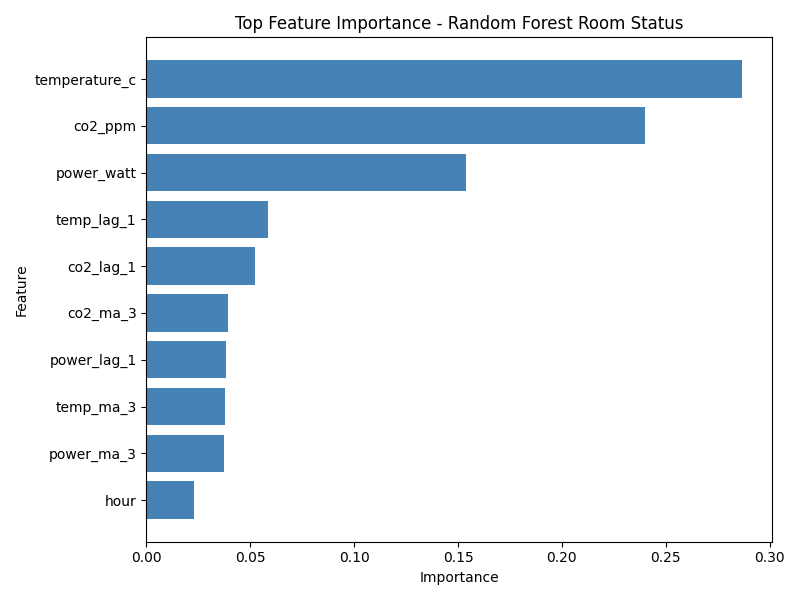

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/feature_importance_room_model.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/feature_importance_room_model.png")

## Penutup

Tiga fitur paling berpengaruh: temperature_c (0.29), co2_ppm (0.24), power_watt (0.15).
Model masuk akal secara domain: status ruangan ditentukan kombinasi kondisi lingkungan
dan beban listrik, bukan satu sensor. Feature importance menjadi jembatan ringan antara
model dan operator tanpa perlu SHAP/LIME. Laporan di
`outputs/reports/feature_importance_room_model.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 35 dalam urutan buku) agar dapat dijadikan panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 8. Insight penting Hands-on 33

Latihan ini mengajarkan bahwa:
- explain ability tidak harus rumit,
- model yang lebih “kuat” tetap bisa dijelaskan secara ringan,
- dan feature importance sangat membantu jembatan antara data scientist dan
operator.